# Principal Component Analysis (PCA) of European Protein Consumption

| Key              | Value                                                                                                                                                                                                                                                                                                            |
|:-----------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Week07** | Dimensionality Reduction in Machine Learning                                                                                                                                                                                                                                                                                           |
| **Course Names** | Machine Learning and Data Science.                                                                                                                                                                                               |
| **Submission Deadline**     | November 4, 2026, 11:55 PM                                                                                                                                                                                                                                                                                         |
| **Student Name - Number     | Edward Chisaka - 1774058                                                                                                                                                                                                                                                                                                    |
| **Contact**      | edward.chisaka@stud.hslu.ch                                                                                                                                                                                                                                                                                           |
| **Note**         | The link directs to the specific GitHub file for this _Week05_ Lab implementation exercise.<br/> **_PCA –_**.<br/> _Principal Component Analysis of European protein consumption_. <br/> GitHub citation: [BibTeX](https://github.com/CH-CHISAKA/Machine_Learning_and_Data_Science/tree/main/04-assignments/07-assignment) |

# Import Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA

try:
    from adjustText import adjust_text      # optional: keeps point labels from overlapping
except ImportError:
    adjust_text = None

# ---- plot style: quiet grid, text in ink colours, one blue for the data ----
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110,
})
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", RED])

In [4]:
# Load the data
path = Path('data/protein.csv')
df = pd.read_csv(path)
print(f"{df.shape[0]} rows (countries) x {df.shape[1]} columns")
# df.head()
df

25 rows (countries) x 10 columns


,Country,RedMeat,WhiteMeat,Eggs,Milk,Fish,Cereals,Starch,Nuts,Fr&Veg
0,Albania,10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
1,Austria,8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
2,Belgium,13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
3,Bulgaria,7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
4,Czechoslovakia,9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0
5,Denmark,10.6,10.8,3.7,25.0,9.9,21.9,4.8,0.7,2.4
6,E Germany,8.4,11.6,3.7,11.1,5.4,24.6,6.5,0.8,3.6
7,Finland,9.5,4.9,2.7,33.7,5.8,26.3,5.1,1.0,1.4
8,France,18.0,9.9,3.3,19.5,5.7,28.1,4.8,2.4,6.5
9,Greece,10.2,3.0,2.8,17.6,5.9,41.7,2.2,7.8,6.5


# Exploratory Data Analysis

In [5]:
features =  [c for c in df.columns if c not in ['Country']]
# print(features)

X = df[features]

print("Column types:")
print(df.dtypes.to_string(), "\n")
print("Missing values:", int(df.isnull().sum().sum()), "\n")
print("Duplicate rows:", int(df.duplicated().sum()), "\n" )
print("Duplicate countries:", int(df["Country"].duplicated().sum()))
X.describe().T.round(2)


Column types:
Country          str
RedMeat      float64
WhiteMeat    float64
Eggs         float64
Milk         float64
Fish         float64
Cereals      float64
Starch       float64
Nuts         float64
Fr&Veg       float64 

Missing values: 0 

Duplicate rows: 0 

Duplicate countries: 0


,count,mean,std,min,25%,50%,75%,max
RedMeat,25.0,9.83,3.35,4.4,7.8,9.5,10.6,18.0
WhiteMeat,25.0,7.90,3.69,1.4,4.9,7.8,10.8,14.0
Eggs,25.0,2.94,1.12,0.5,2.7,2.9,3.7,4.7
Milk,25.0,17.11,7.11,4.9,11.1,17.6,23.3,33.7
Fish,25.0,4.28,3.40,0.2,2.1,3.4,5.8,14.2
Cereals,25.0,32.25,10.97,18.6,24.3,28.0,40.1,56.7
Starch,25.0,4.28,1.63,0.6,3.1,4.7,5.7,6.5
Nuts,25.0,3.07,1.99,0.7,1.5,2.4,4.7,7.8
Fr&Veg,25.0,4.14,1.80,1.4,2.9,3.8,4.9,7.9


**Distributions**. Histograms of each variable 
- (25 observation)

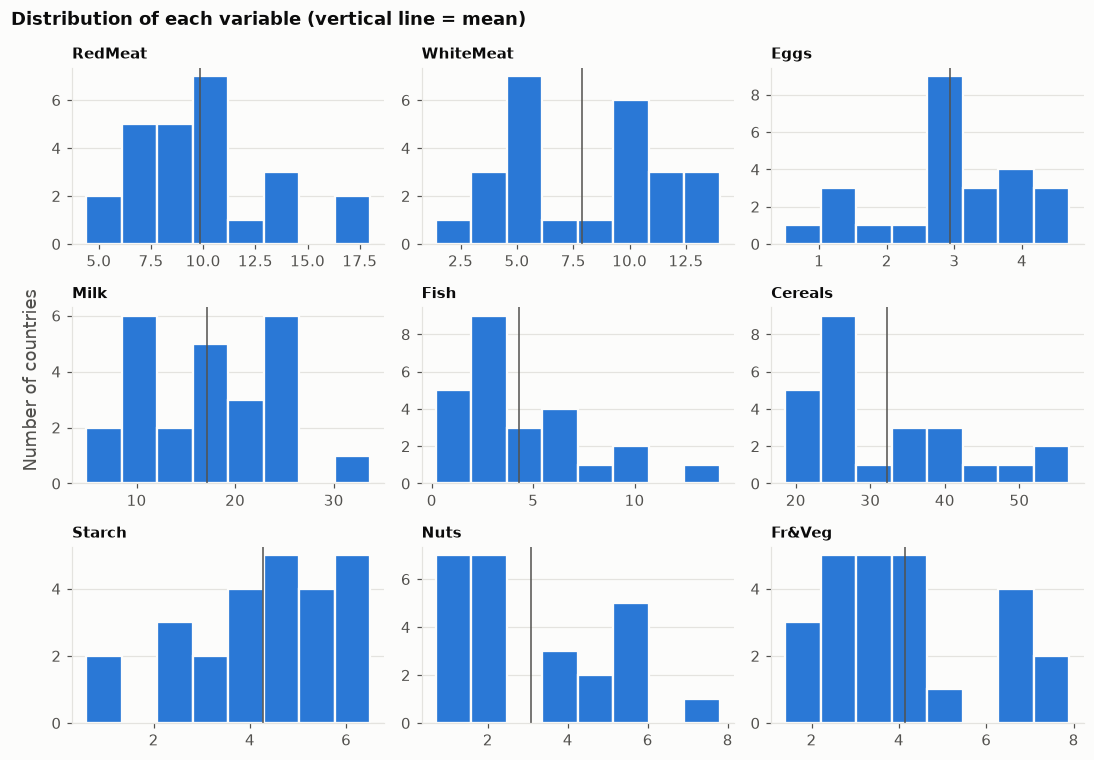

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(10, 7))
for ax, col in zip(axes.ravel(), features):
    ax.hist(X[col], bins=8, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(X[col].mean(), color=INK2, lw=1)             # mean marker
    ax.set_title(col, fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribution of each variable (vertical line = mean)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.supylabel("Number of countries", color=INK2)
fig.tight_layout()
plt.show()

**Scale of the Variables**: 

PCA looks for directions where the data varies the most. However, if some variables have much larger numerical values than others, they can dominate the PCA results. 

Therefore, comparing the spread of the variables to determine whether standardization is necessary will ensure that standardization ensures PCA identifies meaningful patterns in the data rather than simply favouring variables with larger numerical scales.


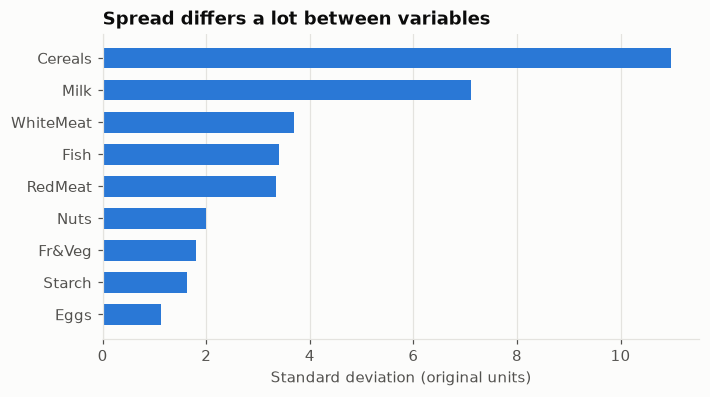

,mean,std
Cereals,32.25,10.97
Milk,17.11,7.11
WhiteMeat,7.90,3.69
Fish,4.28,3.40
RedMeat,9.83,3.35
Nuts,3.07,1.99
Fr&Veg,4.14,1.80
Starch,4.28,1.63
Eggs,2.94,1.12


In [7]:
stats = pd.DataFrame({"mean": X.mean(), "std": X.std()}).sort_values("std", ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(stats.index[::-1], stats["std"][::-1], color=BLUE, height=0.65)
ax.set_xlabel("Standard deviation (original units)")
ax.set_title("Spread differs a lot between variables")
ax.grid(axis="y", visible=False)
plt.show()
stats.round(2)

**Correlation Matrix**

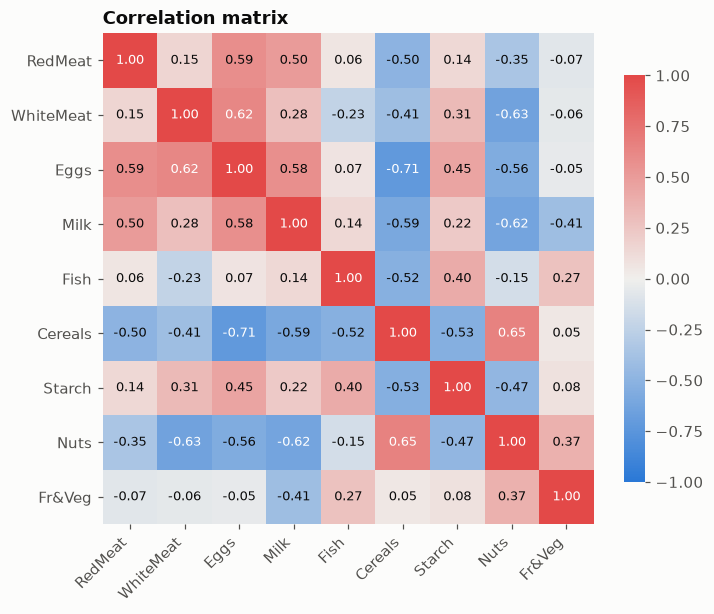

,var 1,var 2,r
0,Eggs,Cereals,-0.71
1,Cereals,Nuts,0.65
2,WhiteMeat,Nuts,-0.63
3,Milk,Nuts,-0.62
4,WhiteMeat,Eggs,0.62
5,Milk,Cereals,-0.59
6,RedMeat,Eggs,0.59
7,Eggs,Milk,0.58


In [8]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), features, rotation=45, ha="right")
ax.set_yticks(range(len(features)), features)
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color=INK if abs(corr.iloc[i, j]) < 0.6 else "white")
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.outline.set_visible(False)
ax.set_title("Correlation matrix")
plt.show()

# strongest pairs
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
             .rename("r").reset_index().rename(columns={"level_0": "var 1", "level_1": "var 2"}))
pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).head(8).round(2).reset_index(drop=True)

# PCA on the standardized variables

Each variable is centred to mean 0 and scaled to standard deviation 1 (z-scores), so that PCA is effectively done on the **correlation matrix**. Total variance is then 9 (one unit per variable), and each principal component's variance is its **eigenvalue**.

In [10]:
Z = ((X - X.mean()) / X.std(ddof=1)).to_numpy()   # z-scores of every variable
print("Column means after scaling:", np.round(Z.mean(axis=0), 10))
print("Column stds  after scaling:", np.round(Z.std(axis=0, ddof=1), 10))

pca = PCA()                                      # keep all 9 components
scores = pca.fit_transform(Z)

pc_names = [f"PC{i}" for i in range(1, len(features) + 1)]
scores_df = pd.DataFrame(scores, columns=pc_names, index=df["Country"])
loadings = pd.DataFrame(pca.components_.T, index=features, columns=pc_names)
print("\nTotal variance (should equal the number of variables):", round(pca.explained_variance_.sum(), 6))

Column means after scaling: [-0.  0.  0. -0.  0. -0.  0.  0. -0.]
Column stds  after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1.]

Total variance (should equal the number of variables): 9.0


<!--  -->

# The data in the new coordinate system

The **scores** are the coordinates of each country along the principal axes.

In [11]:
scores_df.iloc[:, :4].round(2)

,PC1,PC2,PC3,PC4
Country,,,,
Albania,3.49,-1.63,-1.76,0.23
Austria,-1.42,-1.04,1.34,0.17
Belgium,-1.62,0.16,0.22,0.52
Bulgaria,3.13,-1.30,0.15,0.21
Czechoslovakia,-0.37,-0.60,1.20,-0.46
Denmark,-2.37,0.29,-0.75,-0.97
E Germany,-1.42,0.45,1.30,-1.14
Finland,-1.56,-0.60,-2.05,-1.42
France,-1.49,0.79,0.00,1.96


**Scatter plot of PC1 vs PC2**, labelled by country. Axis labels give the share of total variance each component carries.

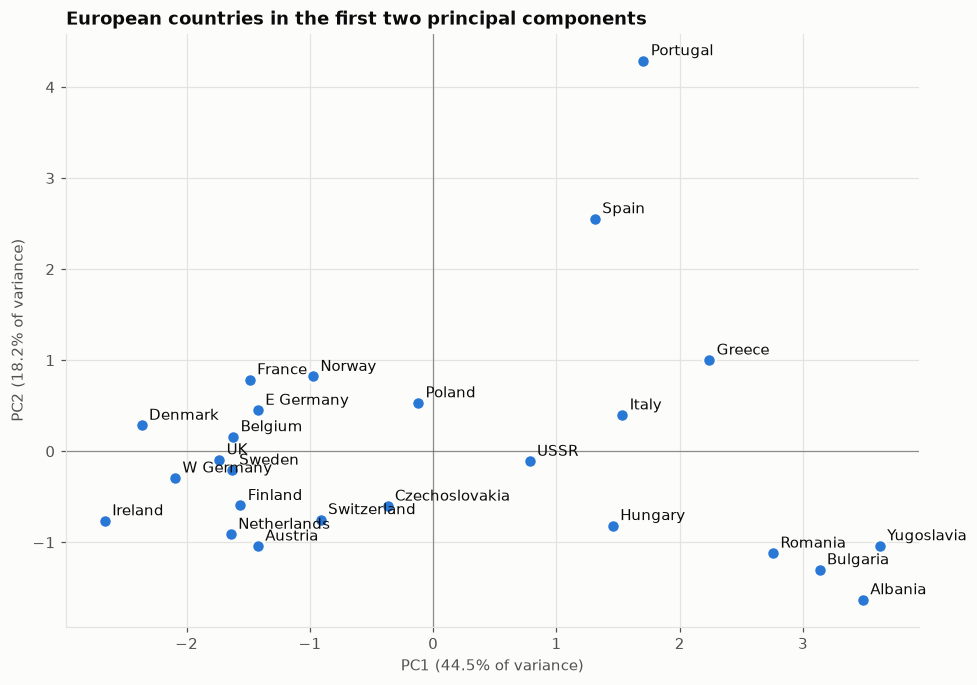

In [12]:
ev = pca.explained_variance_ratio_ * 100
x, y = scores_df["PC1"], scores_df["PC2"]

fig, ax = plt.subplots(figsize=(10, 7))
ax.axhline(0, color=INK2, lw=0.8, alpha=0.6); ax.axvline(0, color=INK2, lw=0.8, alpha=0.6)
ax.scatter(x, y, s=70, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)

texts = [ax.text(xi, yi, name, fontsize=9.5, color=INK) for name, xi, yi in zip(scores_df.index, x, y)]
if adjust_text is not None:
    adjust_text(texts, x=x.values, y=y.values, ax=ax, expand=(1.4, 1.8),
                arrowprops=dict(arrowstyle="-", color=INK2, lw=0.6))
else:                                            # fallback: simple fixed offset
    for t in texts:
        t.set_position((t.get_position()[0] + 0.06, t.get_position()[1] + 0.06))

ax.set_xlabel(f"PC1 ({ev[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({ev[1]:.1f}% of variance)")
ax.set_title("European countries in the first two principal components")
plt.show()

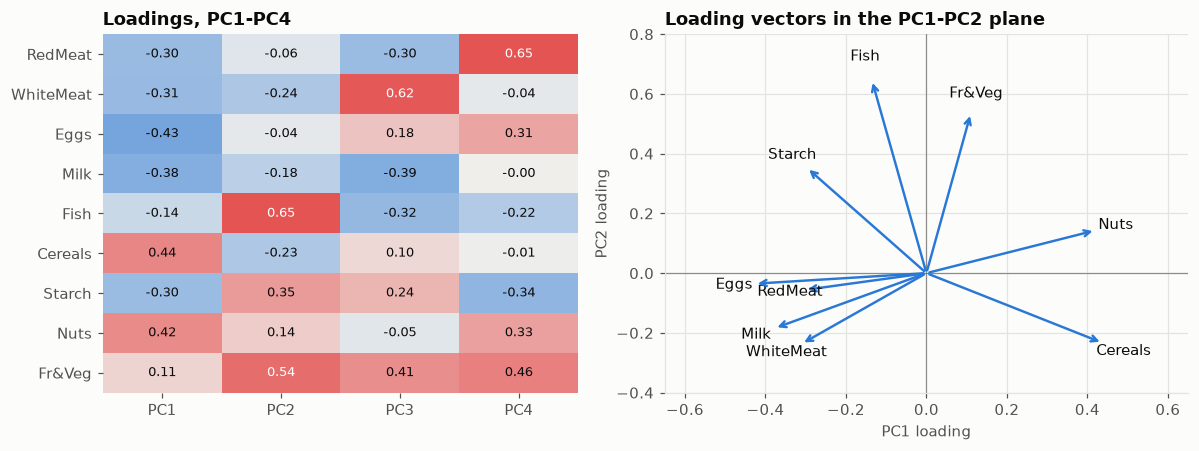

,PC1,PC2,PC3,PC4
RedMeat,-0.303,-0.056,-0.298,0.646
WhiteMeat,-0.311,-0.237,0.624,-0.037
Eggs,-0.427,-0.035,0.182,0.313
Milk,-0.378,-0.185,-0.386,-0.003
Fish,-0.136,0.647,-0.321,-0.216
Cereals,0.438,-0.233,0.096,-0.006
Starch,-0.297,0.353,0.243,-0.337
Nuts,0.420,0.143,-0.054,0.330
Fr&Veg,0.110,0.536,0.408,0.462


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})

# (a) loadings heatmap for the first four PCs
L = loadings.iloc[:, :4]
ax = axes[0]
im = ax.imshow(L, cmap=DIVERGING, vmin=-0.7, vmax=0.7, aspect="auto")
ax.set_xticks(range(4), L.columns); ax.set_yticks(range(len(L)), L.index); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
for i in range(L.shape[0]):
    for j in range(L.shape[1]):
        v = L.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(v) > 0.5 else INK)
ax.set_title("Loadings, PC1-PC4")

# (b) biplot: loading vectors in the PC1/PC2 plane
ax = axes[1]
ax.axhline(0, color=INK2, lw=0.8, alpha=0.6); ax.axvline(0, color=INK2, lw=0.8, alpha=0.6)
for name in features:
    lx, ly = loadings.loc[name, "PC1"], loadings.loc[name, "PC2"]
    ax.annotate("", xy=(lx, ly), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=BLUE, lw=1.6))
    ax.text(lx * 1.12, ly * 1.12, name, ha="center", va="center", fontsize=9.5, color=INK)
ax.set_xlim(-0.65, 0.65); ax.set_ylim(-0.4, 0.8)
ax.set_xlabel("PC1 loading"); ax.set_ylabel("PC2 loading")
ax.set_title("Loading vectors in the PC1-PC2 plane")
fig.tight_layout()
plt.show()

loadings.iloc[:, :4].round(3)

**Summary**

* **PC1 (44.5% of variance)** contrasts animal-based foods with cereals and nuts. Eggs (−0.43), Milk (−0.38), White meat (−0.31), Red meat (−0.30) and Starch (−0.30) load negatively; Cereals (+0.44) and Nuts (+0.42) load positively. Countries on the left (Ireland, Denmark, West Germany, UK, Sweden, Belgium, Netherlands) eat relatively more animal products; countries on the right (Yugoslavia, Albania, Bulgaria, Romania, Greece) rely more on cereals and nuts.
* **PC2 (18.2% of variance)** is mainly Fish (+0.65) and Fruit & vegetables (+0.54), with some Starch (+0.35). **Portugal** (very high) and **Spain** stand apart from the rest because of their fish and fruit & vegetable consumption; Portugal is the clearest outlier in the whole plot.
* The countries form a fairly smooth gradient along PC1 from Northern/Western Europe to the Balkans and Eastern Europe, with the Iberian countries separated along PC2.

# Variance

In [14]:
eig = pca.explained_variance_                      # eigenvalues of the correlation matrix
var_pct = pca.explained_variance_ratio_ * 100
cum_pct = np.cumsum(var_pct)

var_table = pd.DataFrame({
    "Eigenvalue": eig,
    "Variance explained (%)": var_pct,
    "Cumulative variance (%)": cum_pct,
}, index=pc_names).round(2)
var_table

,Eigenvalue,Variance explained (%),Cumulative variance (%)
PC1,4.01,44.52,44.52
PC2,1.63,18.17,62.68
PC3,1.13,12.53,75.22
PC4,0.95,10.61,85.82
PC5,0.46,5.15,90.98
PC6,0.33,3.61,94.59
PC7,0.27,3.02,97.61
PC8,0.12,1.29,98.90
PC9,0.10,1.10,100.00


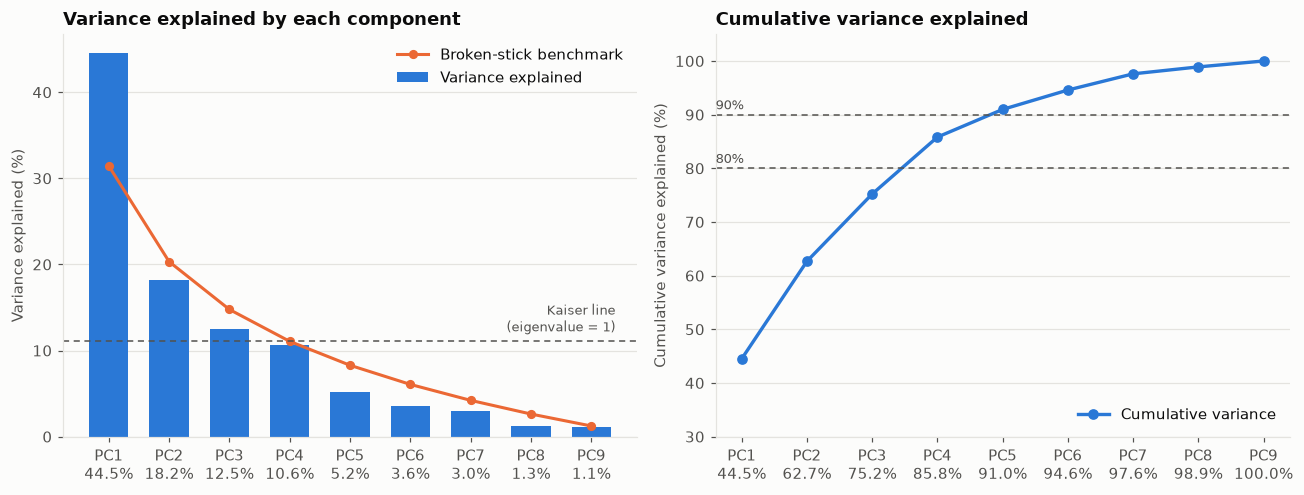

In [15]:
k = np.arange(1, len(pc_names) + 1)
p = len(pc_names)
# broken-stick benchmark: expected % variance if total variance were split at random
broken_stick = np.array([sum(1 / i for i in range(j, p + 1)) for j in k]) / p * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# --- variance explained by each PC (scree) ---
ax = axes[0]
ax.bar(k, var_pct, color=BLUE, width=0.65, label="Variance explained")
ax.plot(k, broken_stick, color=ORANGE, lw=2, marker="o", ms=5, label="Broken-stick benchmark")
ax.axhline(100 / p, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(p + 0.4, 100 / p + 0.6, "Kaiser line\n(eigenvalue = 1)", ha="right", va="bottom",
        fontsize=8.5, color=INK2)
ax.set_xticks(k, [f"{n}\n{v:.1f}%" for n, v in zip(pc_names, var_pct)])
ax.set_ylabel("Variance explained (%)")
ax.set_title("Variance explained by each component")
ax.grid(axis="x", visible=False); ax.legend(frameon=False, loc="upper right")

# --- cumulative ---
ax = axes[1]
ax.plot(k, cum_pct, color=BLUE, lw=2.2, marker="o", ms=6, label="Cumulative variance")
for level in (80, 90):
    ax.axhline(level, color=INK2, lw=1, ls=(0, (4, 3)))
    ax.text(0.6, level + 1, f"{level}%", ha="left", fontsize=8.5, color=INK2)
ax.set_xticks(k, [f"{n}\n{v:.1f}%" for n, v in zip(pc_names, cum_pct)]); ax.set_ylim(30, 105)
ax.set_ylabel("Cumulative variance explained (%)")
ax.set_title("Cumulative variance explained")
ax.grid(axis="x", visible=False); ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
plt.show()

In [16]:
rules = {
    "Kaiser (eigenvalue > 1)": int((eig > 1).sum()),
    "Cumulative variance >= 80%": int(np.argmax(cum_pct >= 80) + 1),
    "Cumulative variance >= 90%": int(np.argmax(cum_pct >= 90) + 1),
    "Broken-stick (PC explains more than chance)": int(np.argmin(var_pct > broken_stick)),
}
print(pd.Series(rules, name="components suggested").to_string())

print("\nEigenvalues:", np.round(eig, 3))
print("Drop between successive eigenvalues:", np.round(-np.diff(eig), 3))

Kaiser (eigenvalue > 1)                        3
Cumulative variance >= 80%                     4
Cumulative variance >= 90%                     5
Broken-stick (PC explains more than chance)    1

Eigenvalues: [4.006 1.635 1.128 0.955 0.464 0.325 0.272 0.116 0.099]
Drop between successive eigenvalues: [2.371 0.507 0.173 0.491 0.139 0.054 0.155 0.017]


### How many components?

| Criterion | Result |
|---|---|
| Kaiser (eigenvalue > 1) | PC1–PC3 exceed 1 (4.01, 1.63, 1.13); PC4 (0.95) falls just below the line, so strictly 3, but it is borderline |
| Cumulative variance | 3 PCs: 75.2%; **4 PCs: 85.8%**; 5 PCs: 91.0% |
| Scree plot | After the big drop from PC1, the last sizeable step down is PC4 → PC5, where the eigenvalue roughly halves (0.95 → 0.46); beyond that every step is below 0.16 and PC5–PC9 each explain at most 5.2% |
| Broken stick | Suggests only PC1, but this rule is known to be very conservative |

**Reasoning.** Four components reduce the problem from 9 to 4 dimensions while keeping about 86% of the total variance, which is above the usual 80% rule of thumb. PC4 is only marginally below the Kaiser cut-off, and the scree plot has its elbow there; the components after it each carry less than half the information in a single original standardized variable (eigenvalue < 0.5), so they are mostly small, noisy contrasts. PC1 and PC2 alone (62.7%) are enough for a picture but leave about a third of the information out, including the third and fourth dimensions that still separate countries.

**Caveats.** With 25 countries the later components are estimated with a lot of uncertainty, so if a more parsimonious representation is needed, **3 components (75%)** is a defensible lower bound, and the broken-stick result is a reminder that after PC1 the evidence for each additional component is weaker. Going to 5 components (91%) would add little: it would bring in a component that explains only 5% of the variance.